# Исследование методов градиентного спуска

**Датасет:** `regression_data.csv`, стоимость квартир в **тыс. руб.**

Решение написано заново по заданию. Приоритет — лекции 1–3; для структуры использованы
семинар 2 и ДЗ-3 из [репозитория](https://github.com/ROTNITE/workshop-on-ml).
Оформление трёх основных графиков основано на `regression (2).ipynb`.

Порядок: train → F/t-проверки → корреляции и отбор → 60 конфигураций и LOOCV →
выбор по validation → единственная итоговая проверка победителя на test → выводы.
Код следует запускать сверху вниз. Командная презентация составляется по итоговым
таблицам, графикам и выводам; состав команды здесь не выдумывается.

**Трактовка задания.** «Обучение на val» означает проверку на val и подбор шага после
обучения на train (лекция 2, с. 5–6). При удалении признаков меняется только X;
целевой столбец y и строки остаются. Test не используется для выбора модели.

## Блок 1. Данные и обучение VGD на train

Датасет: 800 квартир, цена в тыс. руб. Разбиение исходного notebook — 480/160/160,
seed=42. ID исключается, день недели кодируется one-hot. X и y масштабируются
только по обучающей части. Функция потерь — MSE со свободным членом.

Предварительный VGD обучается до сходимости с устойчивым постоянным шагом 0.9/L,
где L — максимальное собственное значение матрицы градиента. Независимое решение
МНК служит проверкой сходимости. Сравнительный перебор шагов выполняется в блоке 4.

In [1]:
from pathlib import Path
import json
import sys
import platform
import importlib.metadata

import numpy as np
import pandas as pd
from IPython.display import display, Image as NotebookImage, Markdown

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 70)
pd.set_option('display.float_format', lambda value: f'{value:.7g}')

ROOT = Path.cwd()
WORK = ROOT if (ROOT/'config.json').is_file() else ROOT/'gradient_study'
DATA_FILE = WORK/'data/regression_data.csv'
if not DATA_FILE.is_file():
    raise FileNotFoundError('Откройте notebook в gradient_study или в корне репозитория.')
OUTPUT = WORK / 'outputs'
TABLES, FIGURES = OUTPUT / 'tables', OUTPUT / 'figures'
for directory in (OUTPUT, TABLES, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)
CONFIG = json.loads((WORK / 'config.json').read_text(encoding='utf-8'))
ALPHA = CONFIG['alpha']
CORRELATION_THRESHOLD = CONFIG['correlation_threshold']
CREATE_ANIMATIONS = True
print('Python:', platform.python_version())
print('Шаги:', CONFIG['lambda_grid'])
print('Число вариантов:', len(CONFIG['methods'])*len(CONFIG['schedules'])*len(CONFIG['lambda_grid']))

"""MSE optimizers and lecture statistics. No estimator from sklearn is used."""
from dataclasses import dataclass

import numpy as np
import pandas as pd
from numba import njit
from scipy import stats

METHODS = ('VGD', 'SGD', 'SAG', 'Momentum', 'Adam')


def mse(y, prediction):
    return float(np.mean((np.asarray(y) - prediction) ** 2))


def r2_score_manual(y, prediction):
    y = np.asarray(y, dtype=float)
    total = np.sum((y - y.mean()) ** 2)
    if total <= 0:
        raise ValueError('R² не определён для постоянной целевой переменной.')
    return float(1 - np.sum((y - prediction) ** 2) / total)


def learning_rate(k, initial, schedule):
    if schedule not in ('constant', 'time_decay') or initial <= 0 or k < 0:
        raise ValueError('Нужны k>=0, положительный шаг и известное расписание.')
    # Lecture 2: s0=1, p=0.5; first update uses k=0.
    return initial if schedule == 'constant' else initial / np.sqrt(1 + k)


@njit(cache=False)
def _kernel(X, y, method, initial, decay, max_iter, tolerance, batch_size,
            seed, check_every, divergence_limit):
    """Compiled loops only accelerate the explicit lecture update equations."""
    n, d = X.shape
    np.random.seed(seed)
    w = np.zeros(d)
    momentum = np.zeros(d)
    first = np.zeros(d)
    second = np.zeros(d)
    memory = np.zeros((n, d))
    average = np.zeros(d)
    gram = 2.0 * (X.T @ X) / n
    rhs = 2.0 * (X.T @ y) / n
    gradient = np.zeros(d)
    # Stored losses use standardized y. Conversion to original units is external.
    history = np.empty((max_iter // check_every + 2, 3))
    initial_loss = np.mean(y ** 2)
    history[0] = (0., initial_loss, np.sqrt(np.sum(rhs ** 2)))
    used = 1
    status = 1  # 0 converged, 1 budget exhausted, 2 diverged
    iterations = 0
    beta1_power, beta2_power = 1.0, 1.0
    for k in range(max_iter):
        eta = initial / np.sqrt(1.0 + k) if decay else initial
        gradient[:] = 0.
        if method == 1:
            # Random mini-batch, sampled independently with replacement.
            for _ in range(min(batch_size, n)):
                i = np.random.randint(n)
                residual = np.dot(X[i], w) - y[i]
                for j in range(d):
                    gradient[j] += 2.0 * residual * X[i, j] / min(batch_size, n)
        elif method == 2:
            i = np.random.randint(n)
            residual = np.dot(X[i], w) - y[i]
            for j in range(d):
                new_gradient = 2.0 * residual * X[i, j]
                average[j] += (new_gradient - memory[i, j]) / n
                memory[i, j] = new_gradient
                gradient[j] = average[j]
        else:
            for j in range(d):
                gradient[j] = -rhs[j]
                for h in range(d):
                    gradient[j] += gram[j, h] * w[h]
        beta1_power *= .9
        beta2_power *= .999
        for j in range(d):
            if method == 3:
                # Lecture momentum: h[k+1] = .9*h[k] + eta[k]*g[k].
                momentum[j] = .9 * momentum[j] + eta * gradient[j]
                w[j] -= momentum[j]
            elif method == 4:
                first[j] = .9 * first[j] + .1 * gradient[j]
                second[j] = .999 * second[j] + .001 * gradient[j] ** 2
                corrected_first = first[j] / (1. - beta1_power)
                corrected_second = second[j] / (1. - beta2_power)
                w[j] -= eta * corrected_first / (np.sqrt(corrected_second) + 1e-8)
            else:
                w[j] -= eta * gradient[j]
        iterations = k + 1
        if not np.all(np.isfinite(w)) or np.max(np.abs(w)) > divergence_limit:
            status = 2
            break
        if iterations % check_every == 0 or iterations == max_iter:
            full_gradient = gram @ w - rhs
            # Exact MSE quadratic; avoids rescanning all rows at each check.
            loss = .5 * np.dot(w, gram @ w) - np.dot(rhs, w) + initial_loss
            norm = np.sqrt(np.sum(full_gradient ** 2))
            history[used] = (float(iterations), loss, norm)
            used += 1
            if not np.isfinite(loss) or loss > divergence_limit:
                status = 2
                break
            # Tiny learning rate alone cannot trigger convergence.
            if norm <= tolerance:
                status = 0
                break
    return w, iterations, status, history[:used]


@dataclass
class FitResult:
    weights: np.ndarray
    iterations: int
    status: str
    history: np.ndarray
    x_mean: np.ndarray
    x_scale: np.ndarray
    y_mean: float
    y_scale: float

    def predict(self, X):
        if self.status == 'diverged':
            raise ValueError('Нельзя использовать разошедшуюся модель.')
        design = np.column_stack([np.ones(len(X)), (np.asarray(X) - self.x_mean) / self.x_scale])
        return (design @ self.weights) * self.y_scale + self.y_mean

    def coefficients(self):
        slopes = self.weights[1:] * self.y_scale / self.x_scale
        intercept = self.y_mean + self.weights[0] * self.y_scale - slopes @ self.x_mean
        return np.r_[intercept, slopes]


def fit_gd(X, y, method='VGD', initial=.1, schedule='constant', max_iter=10000,
           tolerance=1e-7, batch_size=32, seed=42, check_every=50,
           divergence_limit=1e12):
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) < 2:
        raise ValueError('X должна быть матрицей; y — вектором той же длины >=2.')
    if not np.isfinite(X).all() or not np.isfinite(y).all():
        raise ValueError('Пропуски и бесконечные значения не допускаются.')
    if method not in METHODS or max_iter < 1 or check_every < 1 or batch_size < 1:
        raise ValueError('Некорректный метод или бюджет обучения.')
    learning_rate(0, initial, schedule)
    x_mean, x_scale = X.mean(axis=0), X.std(axis=0)
    x_scale[x_scale == 0] = 1.
    y_mean, y_scale = float(y.mean()), float(y.std())
    if y_scale == 0:
        raise ValueError('Целевая переменная постоянна.')
    design = np.ascontiguousarray(np.column_stack([np.ones(len(X)), (X-x_mean)/x_scale]))
    normalized_y = np.ascontiguousarray((y-y_mean)/y_scale)
    w, iterations, status, history = _kernel(
        design, normalized_y, METHODS.index(method), float(initial), schedule == 'time_decay',
        int(max_iter), float(tolerance), int(batch_size), int(seed), int(check_every), float(divergence_limit))
    return FitResult(w, iterations, ('converged', 'max_iter', 'diverged')[status],
                     history, x_mean, x_scale, y_mean, y_scale)


def ols_statistics(X, y, alpha=.05, parameters=None):
    """Lecture 3: intercept, C=s²(X'X)^-1, two-sided t and overall F.

    Solve in standardized coordinates for numeric stability. An independently
    trained GD solution can supply parameters after convergence is verified.
    """
    names = list(X.columns)
    values, y = X.to_numpy(dtype=float), np.asarray(y, dtype=float)
    n, k = values.shape
    mean, scale = values.mean(axis=0), values.std(axis=0)
    if n <= k+1 or np.any(scale == 0):
        raise ValueError('Недостаточно наблюдений или есть постоянный признак.')
    design = np.column_stack([np.ones(n), (values-mean)/scale])
    if np.linalg.matrix_rank(design) < k+1:
        raise ValueError('Матрица признаков имеет неполный ранг.')
    standardized, *_ = np.linalg.lstsq(design, y, rcond=None)
    transform = np.eye(k+1)
    transform[0, 1:] = -mean/scale
    transform[1:, 1:] = np.diag(1/scale)
    reference = transform @ standardized
    params = reference if parameters is None else np.asarray(parameters)
    prediction = params[0] + values @ params[1:]
    degrees = n-k-1
    sse = np.sum((y-prediction)**2)
    # QR avoids forming an ill-conditioned inverse in original units.
    _, triangular = np.linalg.qr(design, mode='reduced')
    inverse_r = np.linalg.solve(triangular, np.eye(k+1))
    covariance = transform @ (inverse_r @ inverse_r.T) @ transform.T * (sse/degrees)
    standard_errors = np.sqrt(np.diag(covariance))
    t_values = params / standard_errors
    p_values = 2 * stats.t.sf(np.abs(t_values), degrees)
    critical_t = stats.t.ppf(1-alpha/2, degrees)
    table = pd.DataFrame({
        'Признак': ['const']+names, 'Коэффициент': params, 'Стандартная ошибка': standard_errors,
        't': t_values, 'p_value': p_values, 'Значим': p_values < alpha,
        'CI_low': params-critical_t*standard_errors, 'CI_high': params+critical_t*standard_errors})
    r2 = r2_score_manual(y, prediction)
    f_value = (r2/k) / ((1-r2)/degrees)
    model = {'n': n, 'k': k, 'df_resid': degrees, 'R2_train': r2,
             'F': f_value, 'F_critical': float(stats.f.ppf(1-alpha, k, degrees)),
             'p_value': float(stats.f.sf(f_value, k, degrees)),
             't_critical': float(critical_t), 'SSE': float(sse),
             'Модель значима': bool(f_value > stats.f.ppf(1-alpha, k, degrees))}
    return table, model, reference


def select_features(X, y, alpha=.05, correlation_threshold=.85):
    """Train-only t screening, correlation pruning, then t rechecking.

    One-hot columns are screened individually, as in the source notebook.
    Selection is repeated separately inside every LOOCV training fold.
    """
    current = list(X.columns)
    log = []
    initial, _, _ = ols_statistics(X[current], y, alpha)
    insignificant = initial.loc[(initial['Признак'] != 'const') & ~initial['Значим']]
    for _, row in insignificant.iterrows():
        log.append({'Признак': row['Признак'], 'Причина': 't: p>=alpha', 'Значение': row['p_value']})
        current.remove(row['Признак'])
    if not current:
        raise ValueError('Не осталось значимых признаков.')
    while len(current) > 1:
        correlation = X[current].corr().abs()
        pairs = [(correlation.iloc[i, j], current[i], current[j])
                 for i in range(len(current)) for j in range(i+1, len(current))
                 if correlation.iloc[i, j] >= correlation_threshold]
        if not pairs:
            break
        strength, a, b = max(pairs)
        target_correlation = X[[a, b]].apply(lambda col: np.corrcoef(col, y)[0, 1]).abs()
        removed = b if target_correlation[a] >= target_correlation[b] else a
        current.remove(removed)
        log.append({'Признак': removed, 'Причина': 'корреляционный дубль', 'Значение': strength})
    while len(current) > 1:
        table, _, _ = ols_statistics(X[current], y, alpha)
        candidate = table[table['Признак'] != 'const'].sort_values('p_value').iloc[-1]
        if candidate['p_value'] < alpha:
            break
        current.remove(candidate['Признак'])
        log.append({'Признак': candidate['Признак'], 'Причина': 'повторная t-проверка', 'Значение': candidate['p_value']})
    return current, pd.DataFrame(log, columns=['Признак', 'Причина', 'Значение'])

"""Train/validation/LOOCV protocol and export helpers for the notebook."""
import hashlib
import json
from pathlib import Path
import time

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

try:
    from .methods import METHODS, fit_gd, mse, ols_statistics, r2_score_manual, select_features
except ImportError:
    # This file's definitions are also embedded directly into the notebook.
    pass

TARGET = 'Стоимость_квартиры_тыс_руб'
CATEGORY = 'День_недели_публикации'
IDENTIFIER = 'ID_объекта'


def encode_train(frame, other=None):
    """Categories and output columns are learned on this training frame only."""
    frame = frame.drop(columns=[IDENTIFIER], errors='ignore').copy()
    categories = sorted(frame[CATEGORY].unique())
    frame[CATEGORY] = pd.Categorical(frame[CATEGORY], categories=categories)
    encoded = pd.get_dummies(frame, columns=[CATEGORY], drop_first=True, dtype=float).astype(float)
    if other is None:
        return encoded
    other = other.drop(columns=[IDENTIFIER], errors='ignore').copy()
    if not set(other[CATEGORY]).issubset(categories):
        raise ValueError('В проверочной части есть неизвестные категории.')
    other[CATEGORY] = pd.Categorical(other[CATEGORY], categories=categories)
    transformed = pd.get_dummies(other, columns=[CATEGORY], drop_first=True, dtype=float)
    return encoded, transformed.reindex(columns=encoded.columns, fill_value=0.).astype(float)


def split_dataset(frame, seed=42):
    if TARGET not in frame or frame.isna().any().any():
        raise ValueError('Проверьте целевой столбец и пропуски в данных.')
    if not frame[IDENTIFIER].is_unique:
        raise ValueError('ID объектов должны быть уникальны.')
    # Keep exact original notebook partitions: 60 / 20 / 20.
    train, temporary = train_test_split(frame, test_size=.4, random_state=seed)
    validation, test = train_test_split(temporary, test_size=.5, random_state=seed)
    assert set(train.index).isdisjoint(validation.index)
    assert set(train.index).isdisjoint(test.index)
    assert set(validation.index).isdisjoint(test.index)
    return train, validation, test


def prepare_loocv(X_frame, y, alpha, correlation_threshold):
    """Leave one out, then refit encoder, feature selector and scales inside fit_gd."""
    y = np.asarray(y)
    folds, selections = [], []
    for i in range(len(y)):
        keep = np.arange(len(y)) != i
        a, b = encode_train(X_frame.iloc[keep], X_frame.iloc[[i]])
        features, _ = select_features(a, y[keep], alpha, correlation_threshold)
        folds.append((a[features].to_numpy(), y[keep], b[features].to_numpy(), float(y[i])))
        selections.append(features)
    counts = pd.Series([name for names in selections for name in names]).value_counts()
    stability = counts.rename_axis('Признак').reset_index(name='Выбран в LOOCV folds')
    stability['Доля folds'] = stability['Выбран в LOOCV folds'] / len(y)
    return folds, stability


def step_description(schedule, initial):
    return f'η = {initial:g}' if schedule == 'constant' else f'η(k) = {initial:g}/√(1+k)'


def experiment(X, y, X_validation, y_validation, folds, config, output):
    """No test argument: candidate selection cannot access test metrics."""
    rows, fold_rows, models = [], [], {}
    for method in config['methods']:
        for schedule in config['schedules']:
            for initial in config['lambda_grid']:
                started = time.perf_counter()
                key = f'{method}_{schedule}_{initial:g}'
                options = dict(method=method, initial=initial, schedule=schedule,
                               max_iter=config['max_iter'], tolerance=config['gradient_tolerance'],
                               batch_size=config['batch_size'], seed=config['seed'],
                               check_every=config['check_every'], divergence_limit=config['divergence_limit'])
                model = fit_gd(X, y, **options)
                models[key] = model
                errors, diverged_folds, capped_folds = [], 0, 0
                for i, (a, ya, b, truth) in enumerate(folds):
                    candidate = fit_gd(a, ya, **options)
                    prediction = None if candidate.status == 'diverged' else float(candidate.predict(b)[0])
                    error = None if prediction is None else prediction-truth
                    diverged_folds += int(candidate.status == 'diverged')
                    capped_folds += int(candidate.status == 'max_iter')
                    if error is not None:
                        errors.append(error)
                    fold_rows.append({'Конфигурация': key, 'fold': i, 'y': truth, 'prediction': prediction,
                                      'error': error, 'Статус': candidate.status, 'Итерации': candidate.iterations})
                cv_rmse = float(np.sqrt(np.mean(np.square(errors)))) if diverged_folds == 0 else np.nan
                row = {'Конфигурация': key, 'Метод': method, 'Тип шага': schedule,
                       'lambda': initial, 'Шаг': step_description(schedule, initial),
                       'Статус': model.status, 'Итерации': model.iterations,
                       'CV_folds': len(folds), 'CV_diverged': diverged_folds, 'CV_max_iter': capped_folds,
                       'RMSE_CV': cv_rmse, 'MSE_CV': cv_rmse**2,
                       'R2_train': np.nan, 'MSE_train': np.nan, 'R2_val': np.nan,
                       'MSE_val': np.nan, 'RMSE_val': np.nan}
                if model.status != 'diverged':
                    prediction_train, prediction_val = model.predict(X), model.predict(X_validation)
                    row.update(R2_train=r2_score_manual(y, prediction_train), MSE_train=mse(y, prediction_train),
                               R2_val=r2_score_manual(y_validation, prediction_val),
                               MSE_val=mse(y_validation, prediction_val), RMSE_val=np.sqrt(mse(y_validation, prediction_val)))
                row['Допущен'] = model.status != 'diverged' and diverged_folds == 0
                row['Секунды'] = time.perf_counter()-started
                rows.append(row)
                pd.DataFrame(rows).to_csv(output / 'search_checkpoint.csv', index=False, encoding='utf-8-sig')
                print(f'{len(rows):02d}/60 {key}: val RMSE={row["RMSE_val"]:.3f}, '
                      f'LOOCV={cv_rmse:.3f}, status={model.status}, {row["Секунды"]:.1f}s', flush=True)
    results = pd.DataFrame(rows)
    eligible = results[results['Допущен']].sort_values(['MSE_val', 'RMSE_CV', 'Конфигурация'], kind='stable')
    if eligible.empty:
        raise RuntimeError('Все конфигурации разошлись. См. search_checkpoint.csv.')
    best_per_method = eligible.drop_duplicates('Метод').reset_index(drop=True)
    best_per_type = eligible.drop_duplicates(['Метод', 'Тип шага']).reset_index(drop=True)
    return results, best_per_method, best_per_type, eligible.iloc[0], models, pd.DataFrame(fold_rows)


def export_table(frame, name, directory):
    frame.to_csv(directory / f'{name}.csv', index=False, encoding='utf-8-sig')


def file_sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

"""Static versions of the three charts in regression (2).ipynb."""
from functools import lru_cache
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw, ImageFont


@lru_cache(maxsize=32)
def chart_font(size, bold=False):
    candidates = (
        ['C:/Windows/Fonts/arialbd.ttf', '/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf']
        if bold else
        ['C:/Windows/Fonts/arial.ttf', '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf']
    )
    for path in candidates:
        if Path(path).exists():
            return ImageFont.truetype(path, size)
    raise FileNotFoundError('Для русских подписей установите Arial или DejaVu Sans.')


def new_chart(width, height, title, subtitle):
    image = Image.new('RGB', (width, height), '#ffffff')
    draw = ImageDraw.Draw(image)
    draw.text((28, 22), title, fill='#17263c', font=chart_font(25, True))
    draw.text((28, 60), subtitle, fill='#6f8096', font=chart_font(14))
    return image, draw


def correlation_chart(correlation):
    labels = [name.replace('_', ' ') for name in correlation.columns]
    count = len(labels)
    left, top, size = 310, 110, 46
    image, draw = new_chart(left + count * size + 35, top + count * size + 60,
                           'Корреляции признаков', 'Train · коэффициент Пирсона')
    for i, label in enumerate(labels):
        draw.text((left-12, top+i*size+size//2), f'{i+1}. {label}',
                  fill='#334155', font=chart_font(12), anchor='rm')
        draw.text((left+i*size+size//2, top-18), str(i+1),
                  fill='#334155', font=chart_font(12, True), anchor='mm')
    draw.text((28, top+count*size+22),
              'Синий — положительная связь   ·   Красный — отрицательная',
              fill='#718096', font=chart_font(12))
    for i in range(count):
        for j in range(count):
            value = correlation.iloc[i, j]
            strength = abs(value)
            color = ((int(245-180*strength), int(248-105*strength), int(252-30*strength))
                     if value >= 0 else
                     (int(252-25*strength), int(246-145*strength), int(245-130*strength)))
            x, y = left+j*size, top+i*size
            draw.rounded_rectangle((x, y, x+size-3, y+size-3), radius=6, fill=color)
            draw.text((x+size//2, y+size//2), f'{value:.2f}',
                      fill='white' if strength > .65 else '#263449',
                      font=chart_font(12), anchor='mm')
    return image


def comparison_chart(best_by_method, metric='RMSE_CV', cv_name='LOOCV'):
    rows = best_by_method.sort_values(metric, kind='stable')
    maximum = rows[metric].max() * 1.18
    image, draw = new_chart(760, 425, 'Сравнение методов',
                           f'Лучшая конфигурация каждого метода · {cv_name} · меньше — лучше')
    left, top, width = 145, 105, 500
    for i, (_, row) in enumerate(rows.iterrows()):
        y = top+i*57
        bar_width = width*row[metric]/maximum
        draw.text((left-15, y+15), row['Метод'], fill='#334155',
                  font=chart_font(15, True), anchor='rm')
        draw.rounded_rectangle((left, y, left+width, y+30), radius=6, fill='#f3f6fa')
        if bar_width >= 1:
            draw.rounded_rectangle((left, y, left+bar_width, y+30),
                                   radius=min(6, bar_width/2),
                                   fill='#2563eb' if i == 0 else '#a8c6ef')
        draw.text((left+bar_width+10, y+15), f'{row[metric]:.2f}',
                  fill='#263449', font=chart_font(13, True), anchor='lm')
    draw.text((left, 395), 'RMSE, тыс. руб. · шкала от нуля',
              fill='#718096', font=chart_font(12))
    return image


def prediction_chart(actual, predicted, r2, rmse, show_points=True):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
    pad = max((hi-lo)*.04, 1.)
    lo, hi = lo-pad, hi+pad
    left, top, side = 110, 115, 400
    def coord_x(v):
        return left+(v-lo)/(hi-lo)*side
    def coord_y(v):
        return top+side-(v-lo)/(hi-lo)*side
    image, draw = new_chart(760, 590, 'Прогноз на тестовой выборке',
                           f'R² = {r2:.4f}  ·  RMSE = {rmse:.1f} тыс. руб.')
    for tick in np.linspace(lo, hi, 5):
        x, y = coord_x(tick), coord_y(tick)
        draw.line((x, top, x, top+side), fill='#e8edf4')
        draw.line((left, y, left+side, y), fill='#e8edf4')
        label = f'{tick:,.0f}'.replace(',', ' ')
        draw.text((x, top+side+10), label, fill='#718096', font=chart_font(11), anchor='mt')
        draw.text((left-10, y), label, fill='#718096', font=chart_font(11), anchor='rm')
    draw.line((left, top+side, left+side, top), fill='#ef8d63', width=2)
    draw.text((left, top-25), 'Прогноз, тыс. руб.', fill='#334155', font=chart_font(13))
    draw.text((left+side/2, top+side+42), 'Фактическая стоимость, тыс. руб.',
              fill='#334155', font=chart_font(13), anchor='mt')
    draw.text((left+side+20, top+10), 'Идеальный прогноз', fill='#c76c48', font=chart_font(12))
    layer = Image.new('RGBA', image.size)
    points = ImageDraw.Draw(layer)
    for a, p in zip(actual, predicted) if show_points else []:
        x, y = coord_x(a), coord_y(p)
        radius = 3.4
        points.ellipse((x-radius, y-radius, x+radius, y+radius), fill=(37, 99, 190, 210))
    image.paste(layer, (0, 0), layer)
    return image

df = pd.read_csv(DATA_FILE)
train, validation, test = split_dataset(df, CONFIG['seed'])
X_train_raw = train.drop(columns=[TARGET])
X_val_raw = validation.drop(columns=[TARGET])
y_train, y_val = train[TARGET].to_numpy(), validation[TARGET].to_numpy()
X_encoded, X_val_encoded = encode_train(X_train_raw, X_val_raw)

split_table = pd.DataFrame({'Выборка': ['train', 'validation', 'test'],
                            'Объекты': [len(train), len(validation), len(test)],
                            'Доля': [len(train)/len(df), len(validation)/len(df), len(test)/len(df)]})
display(df.head())
display(split_table)
print('Размер датасета:', df.shape, 'Пропуски:', df.isna().sum().sum())
membership = pd.concat([part[[IDENTIFIER]].assign(Выборка=name)
                        for name, part in [('train', train), ('validation', validation), ('test', test)]])
export_table(membership, 'split_membership', TABLES)
export_table(split_table, 'splits', TABLES)

values = X_encoded.to_numpy()
standardized = (values-values.mean(axis=0))/values.std(axis=0)
design = np.column_stack([np.ones(len(values)), standardized])
lipschitz = np.linalg.eigvalsh(2*design.T@design/len(design)).max()
baseline = fit_gd(values, y_train, method='VGD', initial=.9/lipschitz,
                  max_iter=CONFIG['baseline_max_iter'], tolerance=CONFIG['baseline_tolerance'],
                  seed=CONFIG['seed'])
if baseline.status != 'converged':
    raise RuntimeError('VGD не сошёлся: F/t-проверки нельзя выдавать за точные проверки МНК.')

print('VGD обучен:', baseline.status, 'итераций:', baseline.iterations)

Python: 3.12.10
Шаги: [1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0]
Число вариантов: 60


,ID_объекта,Общая_площадь_м2,Жилая_площадь_м2,Количество_комнат,Этаж,Год_постройки,Расстояние_до_метро_мин,Расстояние_до_метро_м,Номер_подъезда,Код_домофона,День_недели_публикации,Случайный_показатель_шум,Стоимость_квартиры_тыс_руб
0,10001,69.9,46.2,2,2,2020,10.2,813,6,684,Чт,42.18,14785.1
1,10002,134.5,78.9,5,11,1984,23.1,1866,4,968,Пн,44.52,23038.5
2,10003,110,66.2,5,10,2010,24,2025,5,567,Пт,44.82,20917.6
3,10004,95,59.7,4,15,2008,7.4,516,7,965,Ср,52.59,19347.4
4,10005,45.5,27,3,17,1971,20.6,1706,9,637,Пн,31.69,8173.2


,Выборка,Объекты,Доля
0,train,480,0.6
1,validation,160,0.2
2,test,160,0.2


Размер датасета: (800, 13) Пропуски: 0


VGD обучен: converged итераций: 23250


## Блок 2. Значимость модели и признаков

Проверки выполняются только на train для сошедшегося VGD. Предсказания VGD и МНК
сверяются с допуском 0.001 тыс. руб.

**F:** $H_0:b_1=\dots=b_k=0$, $H_1$ — хотя бы один коэффициент ненулевой.
$F=(R^2/k)/((1-R^2)/(n-k-1))$, сравниваем с $F_{0.95}(k,n-k-1)$.

**t:** $H_0:b_i=0$ против $H_1:b_i\ne0$.
$C=s_e^2(X^TX)^{-1}$, $s_e^2=SSE/(n-k-1)$, $t_i=b_i/\sqrt{C_{ii}}$.
Двусторонний уровень α=0.05 (лекция 3, с. 1–2). В следующем блоке незначимые
признаки исключаются программно. Отсутствие значимости не доказывает нулевой эффект.

In [2]:
full_significance, full_model_stats, ols_parameters = ols_statistics(
    X_encoded, y_train, ALPHA, baseline.coefficients())
ols_prediction = ols_parameters[0] + values@ols_parameters[1:]
baseline_difference = float(np.max(np.abs(baseline.predict(values)-ols_prediction)))
assert baseline_difference < .001, 'VGD ещё недостаточно близок к МНК.'
print('Предварительный VGD: шаг =', .9/lipschitz, 'итераций =', baseline.iterations)
print('Максимальное расхождение прогнозов VGD и МНК, тыс. руб.:', baseline_difference)
display(pd.DataFrame([full_model_stats]))
display(full_significance)
export_table(full_significance, 'significance_full', TABLES)

Предварительный VGD: шаг = 0.15539409150036762 итераций = 23250
Максимальное расхождение прогнозов VGD и МНК, тыс. руб.: 2.124146521964576e-05


,n,k,df_resid,R2_train,F,F_critical,p_value,t_critical,SSE,Модель значима
0,480,16,463,0.9938612,4684.913,1.665385,0,1.965101,9.895796e+07,True


,Признак,Коэффициент,Стандартная ошибка,t,p_value,Значим,CI_low,CI_high
0,const,-88738.82,2747.442,-32.2987,1.122051e-120,True,-94137.82,-83339.82
1,Общая_площадь_м2,179.6399,3.506181,51.23522,6.670864e-193,True,172.7499,186.5299
2,Жилая_площадь_м2,-3.613969,5.040942,-0.7169234,0.4737829,False,-13.51993,6.291991
3,Количество_комнат,-34.63025,40.73903,-0.8500509,0.3957361,False,-114.6866,45.42606
4,Этаж,24.43115,2.923738,8.356134,7.618798e-16,True,18.68571,30.17659
5,Год_постройки,45.73341,1.369418,33.39624,2.210489e-125,True,43.04237,48.42446
6,Расстояние_до_метро_мин,-70.25522,35.17268,-1.997437,0.04636243,True,-139.3731,-1.137345
7,Расстояние_до_метро_м,-0.3432388,0.4387934,-0.7822333,0.4344773,False,-1.205512,0.5190344
8,Номер_подъезда,16.86068,8.081711,2.086277,0.03750026,True,0.9793072,32.74206
9,Код_домофона,-0.04761187,0.08345083,-0.570538,0.5685896,False,-0.2116012,0.1163774


## Блок 3. Корреляции и окончательный набор признаков

По t-критерию исключаем признаки с $p\ge0.05$, сохраняя свободный член.
Строим полную числовую матрицу корреляций, как в исходном notebook, и таблицу
корреляций оставшихся признаков. Заранее задаём порог избыточности $|r|\ge0.85$.
Если после t-отбора такая пара осталась, сохраняем признак с большей
$|r(x,y)|$ на train, затем повторно проверяем значимость сокращённой модели.

Категориальные индикаторы проверяются по отдельности. Отбор разведочный:
множественные проверки и повторный отбор ограничивают интерпретацию p-value.
Парная корреляция отражает линейную связь, не причинность и не отдельный вклад
признака в многомерную модель. Нельзя удалить полезный признак только за слабую связь с y.

Оставлены: ['Общая_площадь_м2', 'Этаж', 'Год_постройки', 'Расстояние_до_метро_мин', 'Номер_подъезда']


,Признак,Причина,Значение
0,Жилая_площадь_м2,t: p>=alpha,0.4737829
1,Количество_комнат,t: p>=alpha,0.3957361
2,Расстояние_до_метро_м,t: p>=alpha,0.4344775
3,Код_домофона,t: p>=alpha,0.5685896
4,Случайный_показатель_шум,t: p>=alpha,0.4606049
5,День_недели_публикации_Вт,t: p>=alpha,0.4450446
6,День_недели_публикации_Пн,t: p>=alpha,0.9608979
7,День_недели_публикации_Пт,t: p>=alpha,0.6196547
8,День_недели_публикации_Сб,t: p>=alpha,0.1571966
9,День_недели_публикации_Ср,t: p>=alpha,0.4535811


,Общая_площадь_м2,Жилая_площадь_м2,Количество_комнат,Этаж,Год_постройки,Расстояние_до_метро_мин,Расстояние_до_метро_м,Номер_подъезда,Код_домофона,Случайный_показатель_шум
Общая_площадь_м2,1,0.9785421,0.9118082,-0.08555299,-0.02961042,0.01334054,0.01775519,-0.003552895,-0.0749925,-0.00728903
Жилая_площадь_м2,0.9785421,1,0.8940571,-0.08134448,-0.04385858,0.01315984,0.01727304,-0.006628928,-0.06835473,0.004566103
Количество_комнат,0.9118082,0.8940571,1,-0.09226012,-0.02243162,0.03769115,0.04292001,-0.0401456,-0.05505117,-0.02889296
Этаж,-0.08555299,-0.08134448,-0.09226012,1,-0.09499125,-0.02190306,-0.02202234,0.07040429,-0.03190565,0.02601655
Год_постройки,-0.02961042,-0.04385858,-0.02243162,-0.09499125,1,-0.05744482,-0.05599376,0.003804871,0.0225901,0.003530484
Расстояние_до_метро_мин,0.01334054,0.01315984,0.03769115,-0.02190306,-0.05744482,1,0.9979695,0.01186924,0.04287769,-0.02864017
Расстояние_до_метро_м,0.01775519,0.01727304,0.04292001,-0.02202234,-0.05599376,0.9979695,1,0.008107385,0.04437337,-0.03004347
Номер_подъезда,-0.003552895,-0.006628928,-0.0401456,0.07040429,0.003804871,0.01186924,0.008107385,1,0.02626495,0.1020363
Код_домофона,-0.0749925,-0.06835473,-0.05505117,-0.03190565,0.0225901,0.04287769,0.04437337,0.02626495,1,0.1087955
Случайный_показатель_шум,-0.00728903,0.004566103,-0.02889296,0.02601655,0.003530484,-0.02864017,-0.03004347,0.1020363,0.1087955,1


,Признак 1,Признак 2,r
0,Общая_площадь_м2,Жилая_площадь_м2,0.9785421
1,Общая_площадь_м2,Количество_комнат,0.9118082
2,Жилая_площадь_м2,Количество_комнат,0.8940571
3,Расстояние_до_метро_мин,Расстояние_до_метро_м,0.9979695


,Общая_площадь_м2,Этаж,Год_постройки,Расстояние_до_метро_мин,Номер_подъезда
Общая_площадь_м2,1,-0.08555299,-0.02961042,0.01334054,-0.003552895
Этаж,-0.08555299,1,-0.09499125,-0.02190306,0.07040429
Год_постройки,-0.02961042,-0.09499125,1,-0.05744482,0.003804871
Расстояние_до_метро_мин,0.01334054,-0.02190306,-0.05744482,1,0.01186924
Номер_подъезда,-0.003552895,0.07040429,0.003804871,0.01186924,1


,n,k,df_resid,R2_train,F,F_critical,p_value,t_critical,SSE,Модель значима
0,480,5,474,0.9937238,15009.85,2.233031,0,1.964981,1.011726e+08,True


,Признак,Коэффициент,Стандартная ошибка,t,p_value,Значим,CI_low,CI_high
0,const,-88353.7,2710.84,-32.59274,4.065017e-123,True,-93680.45,-83026.95
1,Общая_площадь_м2,176.1928,0.6549732,269.0077,0,True,174.9058,177.4798
2,Этаж,24.27305,2.913849,8.330236,8.753235e-16,True,18.54739,29.99871
3,Год_постройки,45.5078,1.352686,33.64254,1.118585e-127,True,42.8498,48.1658
4,Расстояние_до_метро_мин,-97.66833,2.225845,-43.87921,4.866087e-169,True,-102.0421,-93.29459
5,Номер_подъезда,15.65395,7.932678,1.97335,0.04903612,True,0.06638763,31.24151


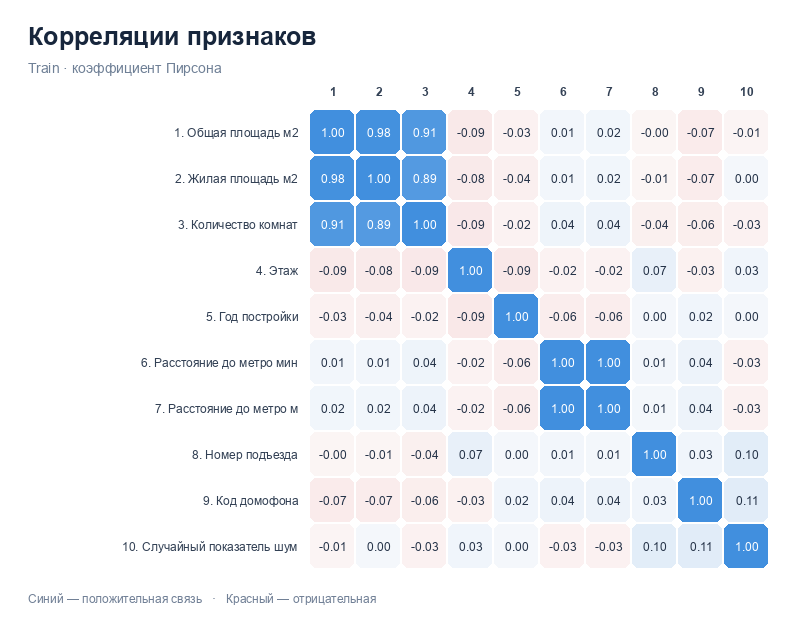

In [3]:
selected_features, selection_log = select_features(X_encoded, y_train, ALPHA, CORRELATION_THRESHOLD)
X_train_new = X_encoded[selected_features]
X_val_new = X_val_encoded[selected_features]
reduced_significance, reduced_model_stats, _ = ols_statistics(X_train_new, y_train, ALPHA)
corr_matrix = X_train_raw.drop(columns=[IDENTIFIER, CATEGORY]).corr()
corr_selected = X_train_new.corr()
feature_target_corr = X_encoded.apply(lambda col: np.corrcoef(col, y_train)[0,1]).rename('r(X,y)')
correlated_pairs = pd.DataFrame([
    {'Признак 1': a, 'Признак 2': b, 'r': corr_matrix.loc[a,b]}
    for i,a in enumerate(corr_matrix.columns) for b in corr_matrix.columns[i+1:]
    if abs(corr_matrix.loc[a,b]) >= CORRELATION_THRESHOLD])
print('Оставлены:', selected_features)
display(selection_log)
display(corr_matrix)
display(correlated_pairs)
display(corr_selected)
display(pd.DataFrame([reduced_model_stats]))
display(reduced_significance)
assert reduced_significance.loc[reduced_significance['Признак']!='const', 'Значим'].all()
assert np.max(np.abs(corr_selected.to_numpy()-np.eye(len(selected_features)))) < CORRELATION_THRESHOLD
export_table(selection_log, 'removed_features', TABLES)
export_table(reduced_significance, 'significance_selected', TABLES)
export_table(pd.DataFrame([{'Этап':'Полная модель', **full_model_stats},
                           {'Этап':'После отбора', **reduced_model_stats}]), 'model_significance', TABLES)
export_table(corr_matrix.rename_axis('Признак').reset_index(), 'correlations_full', TABLES)
export_table(corr_selected.rename_axis('Признак').reset_index(), 'correlations_selected', TABLES)
export_table(feature_target_corr.rename_axis('Признак').reset_index(), 'correlations_target', TABLES)
export_table(correlated_pairs, 'correlated_pairs', TABLES)
export_table(pd.concat([X_train_new, train[TARGET]],axis=1).assign(Выборка='train'), 'train_selected', TABLES)
image = correlation_chart(corr_matrix)
image.save(FIGURES/'01_correlations.png')
display(NotebookImage(filename=str(FIGURES/'01_correlations.png')))

## Блок 4. Сравнение методов, шагов и выбор победителя

Каждая из 60 конфигураций обучается на train и оценивается на validation.
Дополнительно для каждой конфигурации выполняется **настоящая LOOCV внутри train**:
480 обучений на 479 квартирах с прогнозом оставленной квартиры.
В каждом fold заново выполняются кодирование, отбор признаков и масштабирование.
Таким образом, оставленная квартира не влияет даже на выбор признаков.

$LOOCV=\sqrt{\frac1n\sum_i(y_i-\hat y_{-i})^2}$ (лекция 3, с. 3).
Это RMSE в тыс. руб.; MSE имеет единицу $(\text{тыс. руб.})^2$.
$R^2=1-SSE/SST$ — коэффициент детерминации, не «процент точности».

Бюджет — 10 000 обновлений для каждого метода и fold. Остановка раньше возможна
только при норме полного градиента не выше $10^{-7}$. Маленькое изменение потерь
не считается доказательством сходимости. `max_iter` означает исчерпание бюджета,
`diverged` — численную расходимость. Разошедшиеся варианты остаются в таблицах,
но не допускаются к выбору; расходимость хотя бы одного CV-fold исключает вариант.

Число обновлений не равно объёму работы: VGD/Momentum/Adam используют полный
градиент (для квадратичной функции он вычисляется через заранее рассчитанную
матрицу), SGD — 32 случайных наблюдения с повторениями, SAG — одно наблюдение
и память градиентов. По числу итераций нельзя объявлять универсального победителя по скорости.

### Формулы пяти методов

Минимизируем $Q(w)=\frac1n\|Xw-y\|^2$ со свободным членом.
Градиент $g=\frac2nX^T(Xw-y)$.

| Метод | Обновление |
|---|---|
| VGD | $w_{k+1}=w_k-\eta_k g_k$ |
| SGD | тот же шаг по случайному мини-батчу из 32 объектов |
| SAG | пересчитать градиент одного объекта; обновить среднее сохранённых градиентов |
| Momentum | $h_{k+1}=0.9h_k+\eta_k g_k$, $w_{k+1}=w_k-h_{k+1}$ |
| Adam | моменты $\beta_1=0.9$, $\beta_2=0.999$, коррекция смещения, $\varepsilon=10^{-8}$ |

Проверяем **постоянный** шаг $\eta_k=\lambda$ и **функциональный**
$\eta_k=\lambda/\sqrt{1+k}$, $k=0,1,\ldots$ (лекция 2, с. 1–5).
Сетка из семинара 2: $\lambda\in\{10^{-5},10^{-4},10^{-3},10^{-2},10^{-1},1\}$.
«Все шаги» — все значения этой заранее зафиксированной сетки.

Все пять методов реализованы явно. Numba компилирует циклы для ускорения LOOCV,
сами формулы от этого не меняются. И X, и y стандартизуются по обучающей части;
ошибки и коэффициенты возвращаются в исходные единицы.

### Правило выбора

По лекции 2 (с. 5–6) выбираем минимальную **MSE validation** среди допущенных
конфигураций. LOOCV — дополнительная проверка устойчивости; только при точном
равенстве MSE val она разрешает ничью. Таблица для каждого метода содержит
одну реальную конфигурацию со всеми её метриками, а не минимумы из разных строк.
Победитель фиксируется до обращения к test. На validation не дообучаем.

LOOCV folds: 480


,Признак,Выбран в LOOCV folds,Доля folds
0,Общая_площадь_м2,480,1
1,Этаж,480,1
2,Год_постройки,480,1
3,Расстояние_до_метро_мин,403,0.8395833
4,Номер_подъезда,249,0.51875


01/60 VGD_constant_1e-05: val RMSE=4964.277, LOOCV=4778.264, status=max_iter, 1.4s


02/60 VGD_constant_0.0001: val RMSE=932.619, LOOCV=1026.621, status=max_iter, 1.4s


03/60 VGD_constant_0.001: val RMSE=449.129, LOOCV=617.092, status=converged, 1.3s


...

60/60 Adam_time_decay_1: val RMSE=449.129, LOOCV=617.092, status=converged, 0.0s


,Конфигурация,Метод,Тип шага,lambda,Шаг,Статус,Итерации,CV_folds,CV_diverged,CV_max_iter,RMSE_CV,MSE_CV,R2_train,MSE_train,R2_val,MSE_val,RMSE_val,Допущен,Секунды
0,VGD_constant_1e-05,VGD,constant,1e-05,η = 1e-05,max_iter,10000,480,0,480,4778.264,2.28318e+07,0.3256086,2.264834e+07,0.3045093,2.464404e+07,4964.277,True,1.434638
1,VGD_constant_0.0001,VGD,constant,0.0001,η = 0.0001,max_iter,10000,480,0,480,1026.621,1053951,0.9737597,881236.7,0.9754536,869777.9,932.6188,True,1.420213
2,VGD_constant_0.001,VGD,constant,0.001,η = 0.001,converged,9500,480,0,0,617.0924,380803.1,0.9937238,210776.3,0.9943073,201716.5,449.1287,True,1.319553
3,VGD_constant_0.01,VGD,constant,0.01,η = 0.01,converged,950,480,0,0,617.0924,380803.1,0.9937238,210776.3,0.9943073,201716.5,449.1287,True,0.1791282
4,VGD_constant_0.1,VGD,constant,0.1,η = 0.1,converged,100,480,0,0,617.0924,380803.1,0.9937238,210776.3,0.9943073,201716.6,449.1287,True,0.0884127
5,VGD_constant_1,VGD,constant,1,η = 1,diverged,100,480,480,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,0.0749114
6,VGD_time_decay_1e-05,VGD,time_decay,1e-05,η(k) = 1e-05/√(1+k),max_iter,10000,480,0,480,5784.681,3.346253e+07,0.007815101,3.332091e+07,-0.02365389,3.627219e+07,6022.64,True,1.35203
7,VGD_time_decay_0.0001,VGD,time_decay,0.0001,η(k) = 0.0001/√(1+k),max_iter,10000,480,0,480,5585.925,3.120255e+07,0.07542033,3.10505e+07,0.0460986,3.380058e+07,5813.826,True,0.6369362
8,VGD_time_decay_0.001,VGD,time_decay,0.001,η(k) = 0.001/√(1+k),max_iter,10000,480,0,480,3950.072,1.560307e+07,0.5413254,1.540384e+07,0.5277082,1.673521e+07,4090.869,True,0.6417903
9,VGD_time_decay_0.01,VGD,time_decay,0.01,η(k) = 0.01/√(1+k),max_iter,10000,480,0,480,630.0974,397022.7,0.9932387,227066.9,0.9942353,204268.3,451.9605,True,0.6310335


,Метод,Тип шага,lambda,Шаг,R2_train,R2_val,MSE_train,MSE_val,RMSE_val,RMSE_CV,Итерации,Статус,CV_max_iter
0,SAG,constant,0.01,η = 0.01,0.9937237,0.9943096,210778.2,201633.4,449.036,617.0491,10000,max_iter,480
1,Adam,time_decay,0.01,η(k) = 0.01/√(1+k),0.9937238,0.9943073,210776.3,201716.5,449.1286,617.0924,9050,converged,0
2,Momentum,time_decay,0.1,η(k) = 0.1/√(1+k),0.9937238,0.9943073,210776.3,201716.5,449.1286,617.0924,350,converged,0
3,Adam,constant,0.001,η = 0.001,0.9937238,0.9943073,210776.3,201716.5,449.1286,617.0924,4050,converged,0
4,Momentum,constant,1,η = 1,0.9937238,0.9943073,210776.3,201716.5,449.1286,617.0924,350,converged,0
5,VGD,constant,0.001,η = 0.001,0.9937238,0.9943073,210776.3,201716.5,449.1287,617.0924,9500,converged,0
6,VGD,time_decay,0.1,η(k) = 0.1/√(1+k),0.9937238,0.9943073,210776.3,201716.5,449.1287,617.0924,2300,converged,0
7,SAG,time_decay,0.1,η(k) = 0.1/√(1+k),0.9937238,0.9943068,210776.3,201734,449.1481,617.0996,10000,max_iter,480
8,SGD,time_decay,0.1,η(k) = 0.1/√(1+k),0.9937218,0.9943017,210844.2,201914.9,449.3494,616.5302,10000,max_iter,480
9,SGD,constant,0.001,η = 0.001,0.9937218,0.9943015,210843.5,201919.3,449.3543,616.5382,10000,max_iter,480


,Метод,Тип шага,lambda,Шаг,R2_train,R2_val,MSE_train,MSE_val,RMSE_val,RMSE_CV,Итерации,Статус,CV_max_iter
0,SAG,constant,0.01,η = 0.01,0.9937237,0.9943096,210778.2,201633.4,449.036,617.0491,10000,max_iter,480
1,Adam,time_decay,0.01,η(k) = 0.01/√(1+k),0.9937238,0.9943073,210776.3,201716.5,449.1286,617.0924,9050,converged,0
2,Momentum,time_decay,0.1,η(k) = 0.1/√(1+k),0.9937238,0.9943073,210776.3,201716.5,449.1286,617.0924,350,converged,0
3,VGD,constant,0.001,η = 0.001,0.9937238,0.9943073,210776.3,201716.5,449.1287,617.0924,9500,converged,0
4,SGD,time_decay,0.1,η(k) = 0.1/√(1+k),0.9937218,0.9943017,210844.2,201914.9,449.3494,616.5302,10000,max_iter,480


Победитель: SAG η = 0.01
RMSE validation: 449.03603156945496 LOOCV: 617.0491107085853


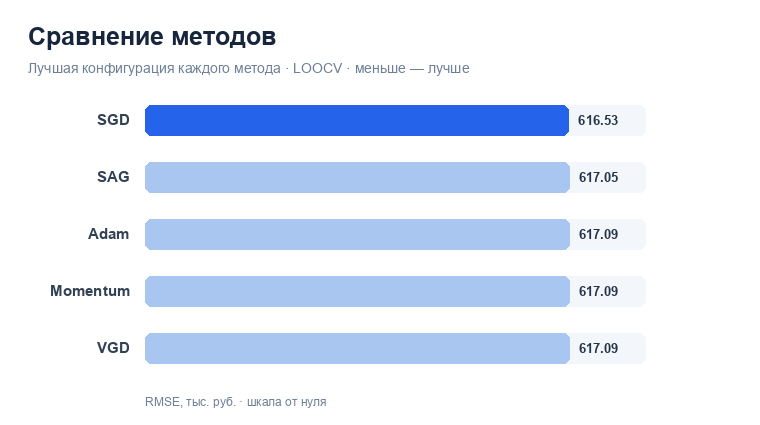

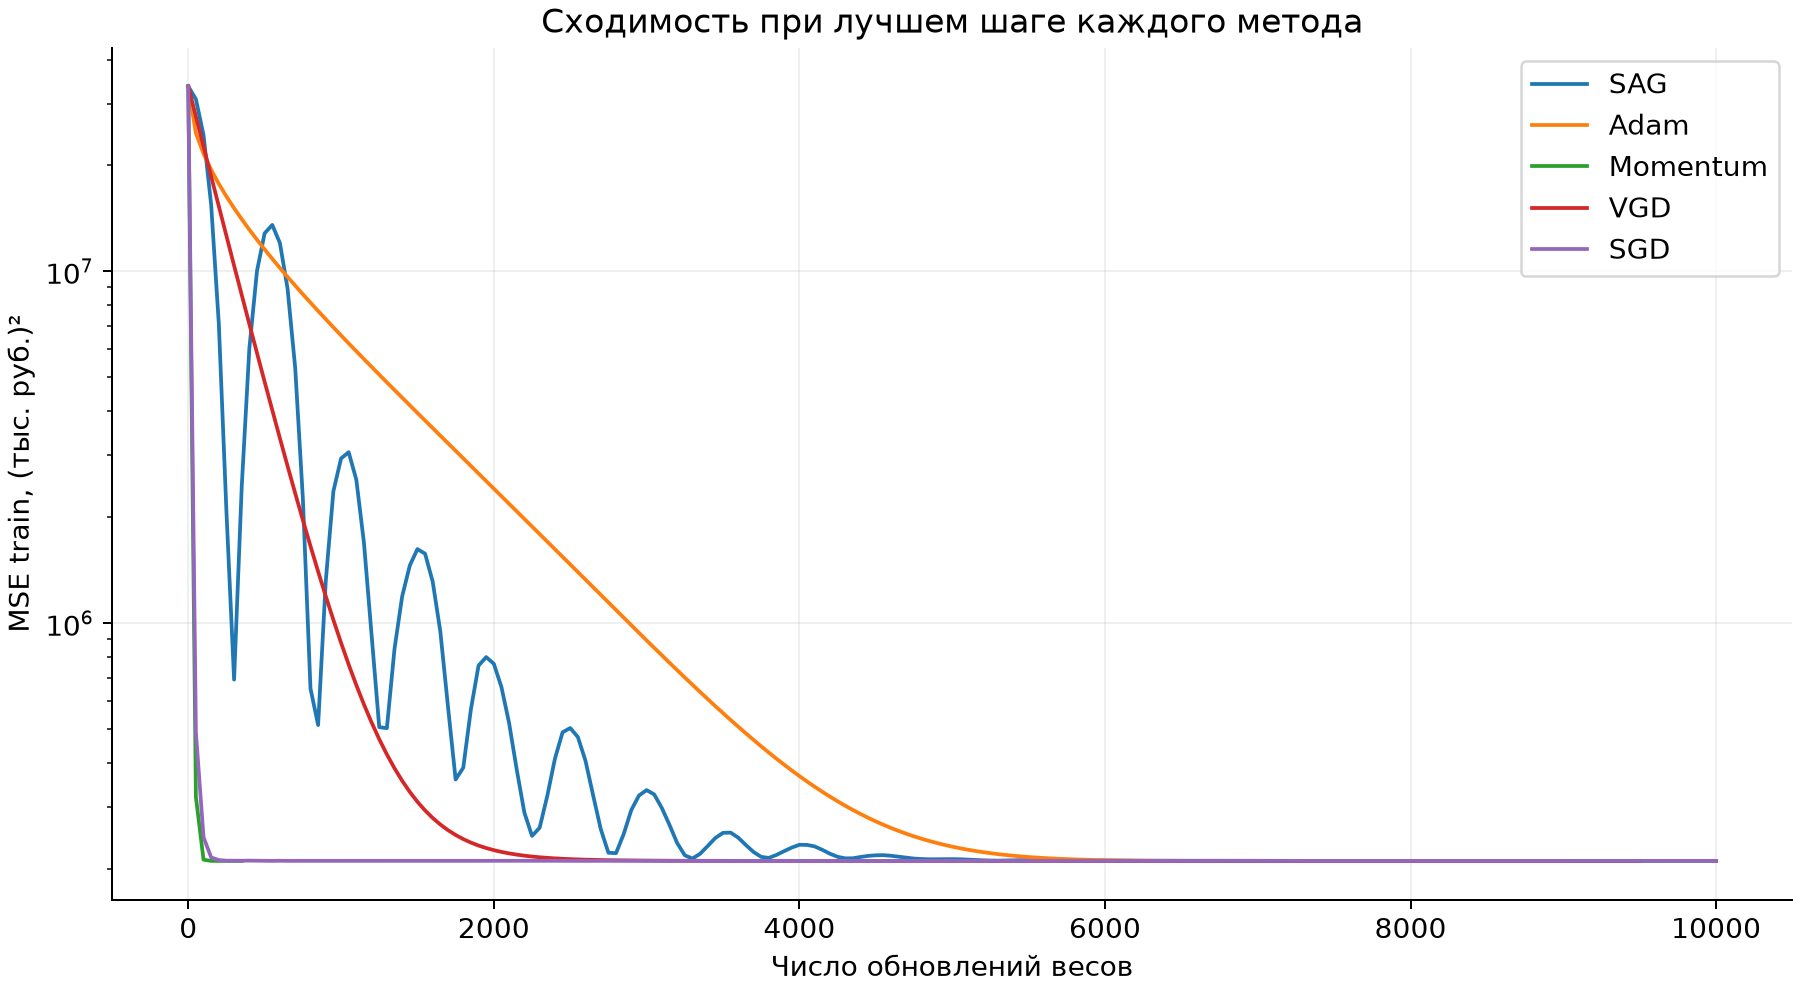

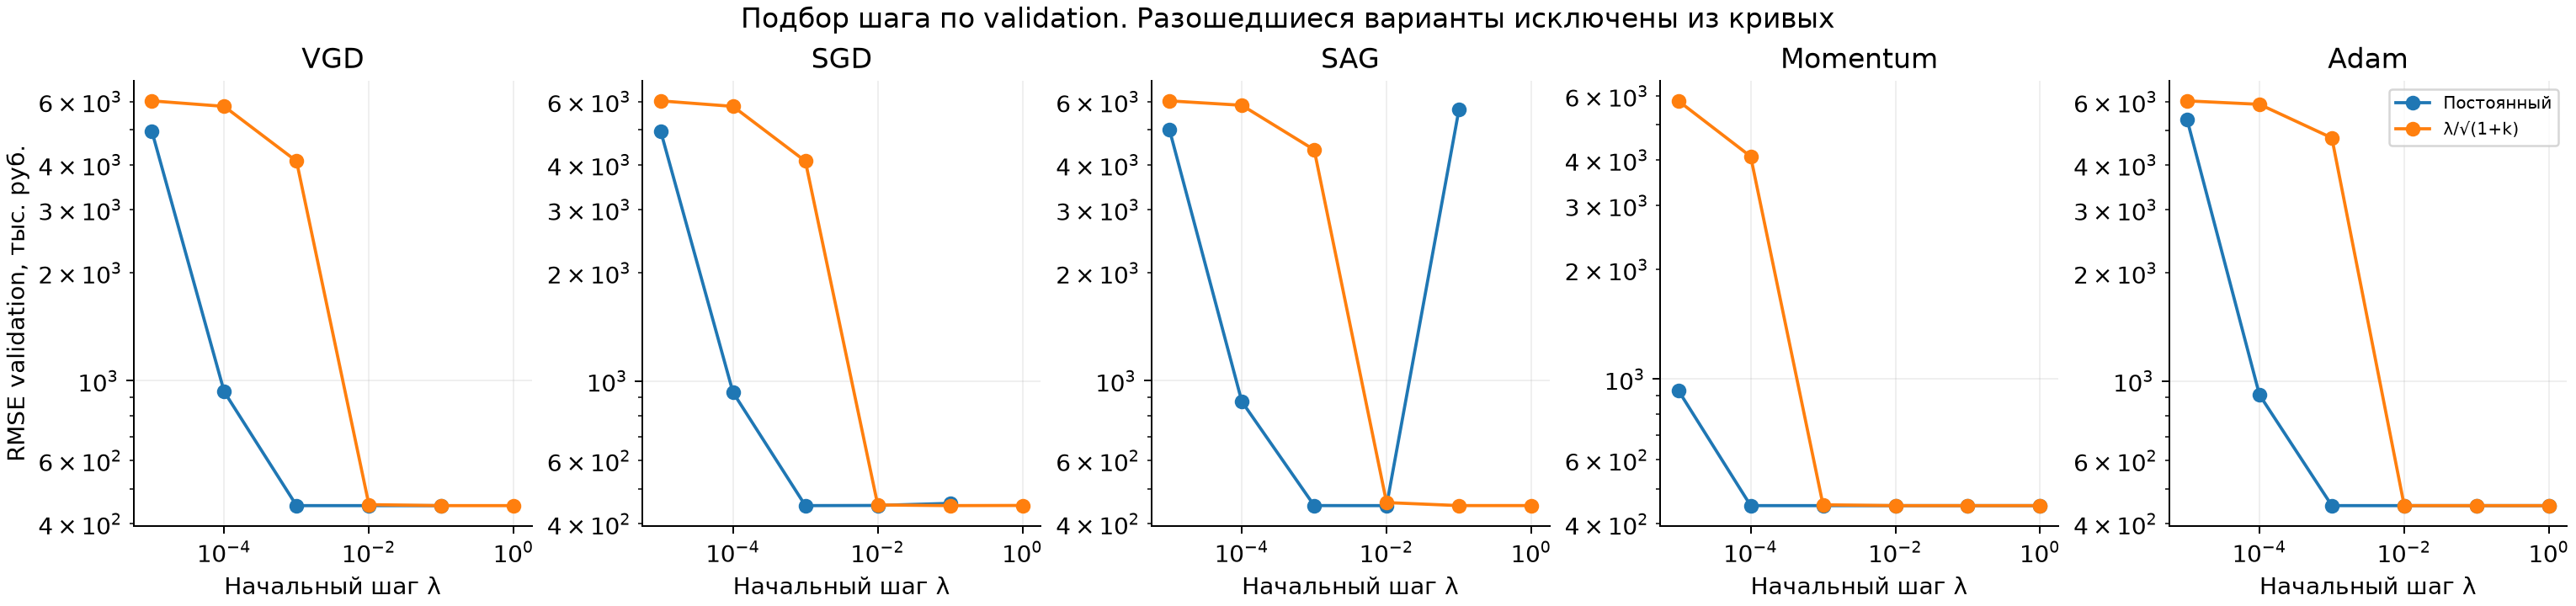

In [4]:
folds, selection_stability = prepare_loocv(X_train_raw, y_train, ALPHA, CORRELATION_THRESHOLD)
print('LOOCV folds:', len(folds))
display(selection_stability)
export_table(selection_stability, 'feature_selection_stability', TABLES)
results_df, best_by_method, best_by_type, best, fitted_models, loocv_details = experiment(
    X_train_new.to_numpy(), y_train, X_val_new.to_numpy(), y_val, folds, CONFIG, OUTPUT)
export_table(results_df, 'all_configurations', TABLES)
export_table(best_by_method, 'best_by_method', TABLES)
export_table(best_by_type, 'best_by_method_and_step', TABLES)
export_table(loocv_details, 'loocv_predictions', TABLES)
display(results_df)

columns = ['Метод','Тип шага','lambda','Шаг','R2_train','R2_val','MSE_train',
           'MSE_val','RMSE_val','RMSE_CV','Итерации','Статус','CV_max_iter']
display(best_by_type[columns])
display(best_by_method[columns])
print('Победитель:', best['Метод'], best['Шаг'])
print('RMSE validation:', best['RMSE_val'], 'LOOCV:', best['RMSE_CV'])
winner = {key: (value.item() if isinstance(value,np.generic) else value)
          for key,value in best.to_dict().items()}
save_json(OUTPUT/'selection_before_test.json', {'features':selected_features, 'winner':winner,
          'selection_rule':'min MSE_val, then RMSE_LOOCV, then stable configuration key',
          'dataset_sha256':file_sha256(DATA_FILE)})
image = comparison_chart(best_by_method)
image.save(FIGURES/'02_methods.png')
display(NotebookImage(filename=str(FIGURES/'02_methods.png')))
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'svg.fonttype':'none'})
fig,ax = plt.subplots(figsize=(10,5.5),layout='constrained')
for _,row in best_by_method.iterrows():
    model = fitted_models[row['Конфигурация']]
    history = model.history
    ax.plot(history[:,0],history[:,1]*model.y_scale**2,label=row['Метод'])
ax.set(xlabel='Число обновлений весов',ylabel='MSE train, (тыс. руб.)²',
       title='Сходимость при лучшем шаге каждого метода',yscale='log')
ax.grid(alpha=.2)
ax.legend()
fig.savefig(FIGURES/'04_convergence.png',dpi=180)
fig.savefig(FIGURES/'04_convergence.svg')
plt.close(fig)
display(NotebookImage(filename=str(FIGURES/'04_convergence.png')))

fig,axes = plt.subplots(1,5,figsize=(17,4),layout='constrained')
for ax,method in zip(axes,CONFIG['methods']):
    for schedule,label in [('constant','Постоянный'),('time_decay','λ/√(1+k)')]:
        rows = results_df[(results_df['Метод']==method)&(results_df['Тип шага']==schedule)].sort_values('lambda')
        valid = rows['Допущен']
        ax.plot(rows.loc[valid,'lambda'],rows.loc[valid,'RMSE_val'],'o-',label=label)
    ax.set(title=method,xscale='log',yscale='log',xlabel='Начальный шаг λ')
    ax.grid(alpha=.2)
axes[0].set_ylabel('RMSE validation, тыс. руб.')
axes[-1].legend(fontsize=8)
fig.suptitle('Подбор шага по validation. Разошедшиеся варианты исключены из кривых')
fig.savefig(FIGURES/'05_step_search.png',dpi=180)
fig.savefig(FIGURES/'05_step_search.svg')
plt.close(fig)
display(NotebookImage(filename=str(FIGURES/'05_step_search.png')))

## Блок 5. Итоговая проверка победителя на test

Используем уже обученную на train модель выбранной конфигурации. Test не меняет
ни признаки, ни шаг, ни число итераций. Константный контрольный прогноз использует
среднюю стоимость на train. Сравнение с ним помогает понять масштаб улучшения.

,Модель,R2_test,MSE_test,RMSE_test,MAE_test
0,SAG,0.9940989,220172.9,469.2258,375.6988
1,Среднее train,-0.01453134,3.785293e+07,6152.474,5267.055


Уравнение в исходных единицах: ŷ = -88432.737495 +176.174084·[Общая_площадь_м2] +24.282654·[Этаж] +45.549342·[Год_постройки] -97.694750·[Расстояние_до_метро_мин] +15.399666·[Номер_подъезда]


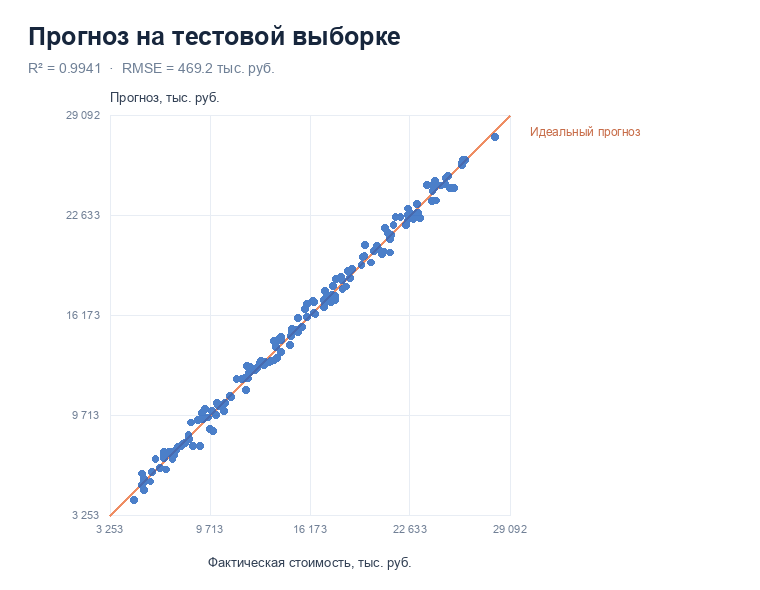

In [5]:
_, X_test_encoded = encode_train(X_train_raw, test.drop(columns=[TARGET]))
X_test_new = X_test_encoded[selected_features]
y_true_test = test[TARGET].to_numpy()
best_model = fitted_models[best['Конфигурация']]
y_pred_test = best_model.predict(X_test_new.to_numpy())
r2_test = r2_score_manual(y_true_test, y_pred_test)
rmse_test = np.sqrt(mse(y_true_test, y_pred_test))
mae_test = float(np.mean(np.abs(y_true_test-y_pred_test)))
constant_prediction = np.full(len(test), y_train.mean())
test_metrics = pd.DataFrame([
    {'Модель':best['Метод'], 'R2_test':r2_test, 'MSE_test':rmse_test**2,
     'RMSE_test':rmse_test, 'MAE_test':mae_test},
    {'Модель':'Среднее train', 'R2_test':r2_score_manual(y_true_test,constant_prediction),
     'MSE_test':mse(y_true_test,constant_prediction),
     'RMSE_test':np.sqrt(mse(y_true_test,constant_prediction)),
     'MAE_test':float(np.mean(np.abs(y_true_test-constant_prediction)))}])
test_predictions = pd.DataFrame({'ID_объекта':test[IDENTIFIER].to_numpy(),
    'Фактическая стоимость':y_true_test, 'Прогноз':y_pred_test,
    'Ошибка':y_true_test-y_pred_test, 'Константный прогноз':constant_prediction})
display(test_metrics)
parameters = best_model.coefficients()
equation = 'ŷ = '+f'{parameters[0]:.6f}'
for name,value in zip(selected_features,parameters[1:]):
    equation += f' {value:+.6f}·[{name}]'
print('Уравнение в исходных единицах:', equation)
export_table(test_metrics, 'test_metrics', TABLES)
export_table(test_predictions, 'test_predictions', TABLES)
save_json(OUTPUT/'best_model.json', {'method':best['Метод'], 'step':best['Шаг'],
    'features':selected_features, 'intercept':float(parameters[0]),
    'coefficients':parameters[1:].tolist(), 'units':'тыс. руб.',
    'R2_test':r2_test,'RMSE_test':float(rmse_test),'MAE_test':mae_test})
image = prediction_chart(y_true_test,y_pred_test,r2_test,rmse_test)
image.save(FIGURES/'03_predictions.png')
display(NotebookImage(filename=str(FIGURES/'03_predictions.png')))

## Вывод. Шестой слайд

Вывод ниже формируется из рассчитанных результатов. Время выполнения и численная
сходимость ограничены данным бюджетом; более низкая validation-ошибка не доказывает
универсального превосходства метода. Все методы решают одну линейную задачу МНК.
При полной сходимости они должны давать близкие прогнозы.

In [6]:
improvement = 1-rmse_test/test_metrics.iloc[1]['RMSE_test']
conclusions = f"""# Выводы

Обработаны {len(df)} квартир. Train: {len(train)}, validation: {len(validation)}, test: {len(test)}.
F-проверка полной модели: F={full_model_stats['F']:.3f}, критическое значение {full_model_stats['F_critical']:.3f}.
Нулевая гипотеза об отсутствии всех линейных связей отвергается при α=0.05.

После t-проверок и контроля корреляций оставлены: {', '.join(selected_features)}.
При удалении признаков столбец y и строки наблюдений сохранены.
Повторная F-проверка: F={reduced_model_stats['F']:.3f}.
Номер подъезда имеет пограничную значимость на этом разбиении; его устойчивость видна в таблице LOOCV-отбора.

Проверены {len(results_df)} конфигураций: пять методов, два типа шага, шесть значений λ.
Для каждой выполнены {len(folds)} LOOCV folds с повторным отбором признаков внутри обучающей части.
По минимальной MSE validation выбран {best['Метод']}, {best['Шаг']}.
RMSE validation = {best['RMSE_val']:.4f} тыс. руб., R² validation = {best['R2_val']:.6f}.
LOOCV RMSE = {best['RMSE_CV']:.4f} тыс. руб.

На независимом test: R²={r2_test:.6f}, RMSE={rmse_test:.4f} тыс. руб., MAE={mae_test:.4f} тыс. руб.
RMSE ниже ошибки прогноза среднего train на {improvement:.2%}.
R² характеризует долю вариации стоимости, объясняемую прогнозом относительно средней линии.
Это не процент точности и не доказательство причинного влияния признаков.

{equation}

Результат ограничен этим датасетом, разбиением, сеткой шагов, seed и бюджетом.
Значимость после отбора разведочная. Классические F/t-проверки предполагают независимые наблюдения,
корректную линейную спецификацию и одинаковую дисперсию ошибок; точные маловыборочные распределения
дополнительно предполагают нормальность ошибок. На реальных ценах обобщение не проверялось.
Малые различия между почти сошедшимися методами не дают основания объявлять один метод лучшим вообще.
"""
(OUTPUT/'conclusions.md').write_text(conclusions,encoding='utf-8')
display(Markdown(conclusions))

provenance = {
    'dataset_sha256':file_sha256(DATA_FILE),
    'original_notebook_sha256':file_sha256(WORK/'sources/regression.original.ipynb'),
    'upstream_repository':'https://github.com/ROTNITE/workshop-on-ml',
    'upstream_commit':'60d25da62512835765c8ce14597a80c6e0e1aa34',
    'python':sys.version, 'config':CONFIG,
    'libraries':{name:importlib.metadata.version(name) for name in
                 ['numpy','pandas','scipy','scikit-learn','numba','matplotlib','pillow']},
    'lectures':{str(p.relative_to(WORK)):file_sha256(p) for p in (WORK/'sources/lectures').glob('*.pdf')},
    'selection_uses_test':False, 'test_evaluated_for':['winner','train_mean_baseline'],
    'loocv_total_fits':len(results_df)*len(folds)}
save_json(OUTPUT/'provenance.json',provenance)
workbook_data = {p.stem:pd.read_csv(p).replace([np.inf,-np.inf],np.nan).astype(object).where(
                   pd.notna(pd.read_csv(p)),None).to_dict(orient='split')
                 for p in TABLES.glob('*.csv') if p.stem not in ['loocv_predictions','train_selected','split_membership']}
save_json(OUTPUT/'workbook_data.json',workbook_data)
print('Результаты сохранены:', OUTPUT)

# Выводы

Обработаны 800 квартир. Train: 480, validation: 160, test: 160.
F-проверка полной модели: F=4684.913, критическое значение 1.665.
Нулевая гипотеза об отсутствии всех линейных связей отвергается при α=0.05.

После t-проверок и контроля корреляций оставлены: Общая_площадь_м2, Этаж, Год_постройки, Расстояние_до_метро_мин, Номер_подъезда.
При удалении признаков столбец y и строки наблюдений сохранены.
Повторная F-проверка: F=15009.854.
Номер подъезда имеет пограничную значимость на этом разбиении; его устойчивость видна в таблице LOOCV-отбора.

Проверены 60 конфигураций: пять методов, два типа шага, шесть значений λ.
Для каждой выполнены 480 LOOCV folds с повторным отбором признаков внутри обучающей части.
По минимальной MSE validation выбран SAG, η = 0.01.
RMSE validation = 449.0360 тыс. руб., R² validation = 0.994310.
LOOCV RMSE = 617.0491 тыс. руб.

На независимом test: R²=0.994099, RMSE=469.2258 тыс. руб., MAE=375.6988 тыс. руб.
RMSE ниже ошибки прогноза среднего train на 92.37%.
R² характеризует долю вариации стоимости, объясняемую прогнозом относительно средней линии.
Это не процент точности и не доказательство причинного влияния признаков.

ŷ = -88432.737495 +176.174084·[Общая_площадь_м2] +24.282654·[Этаж] +45.549342·[Год_постройки] -97.694750·[Расстояние_до_метро_мин] +15.399666·[Номер_подъезда]

Результат ограничен этим датасетом, разбиением, сеткой шагов, seed и бюджетом.
Значимость после отбора разведочная. Классические F/t-проверки предполагают независимые наблюдения,
корректную линейную спецификацию и одинаковую дисперсию ошибок; точные маловыборочные распределения
дополнительно предполагают нормальность ошибок. На реальных ценах обобщение не проверялось.
Малые различия между почти сошедшимися методами не дают основания объявлять один метод лучшим вообще.


Результаты сохранены: C:\Users\rotn1\Documents\ChatGPT\workshop_ml\gradient_study\outputs


## Дополнительно. Три GIF-анимации

Код анимаций сохранён и переписан для новых результатов. Анимации воспроизводятся
один раз, удерживают последний кадр и сохраняются отдельными файлами в
`gradient_study/outputs/animations`. Последний кадр соответствует статическому
графику с небольшой потерей цвета из-за 256-цветной палитры GIF.

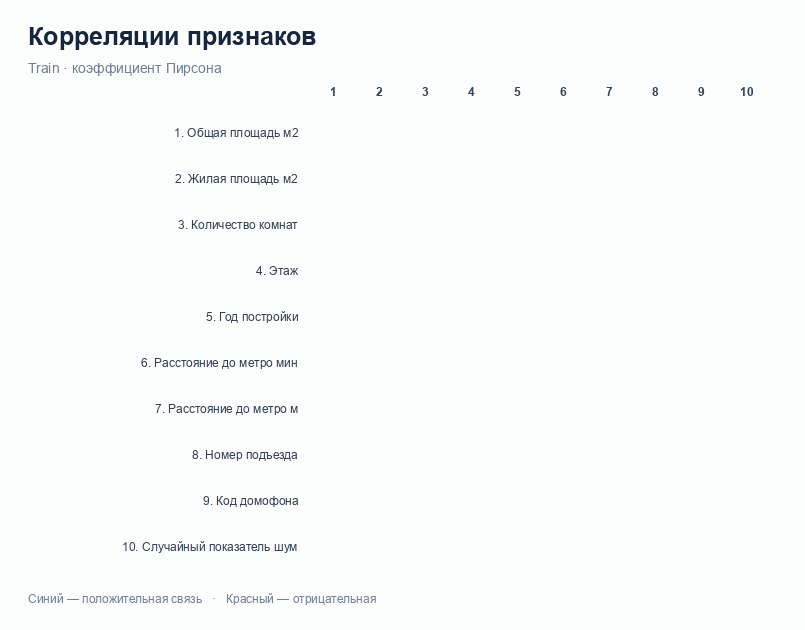

01_correlations.gif


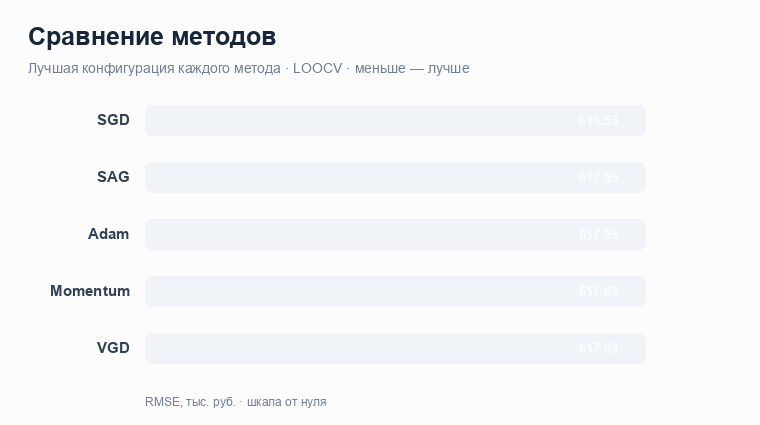

02_methods.gif


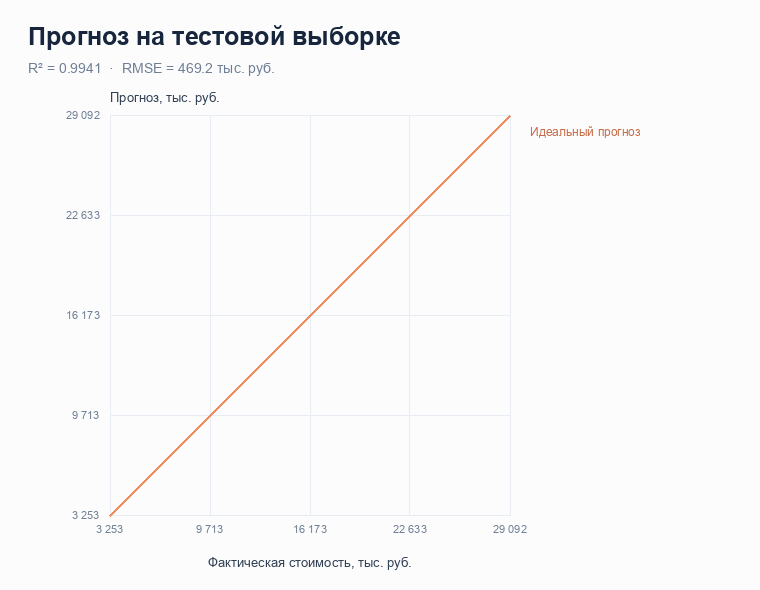

03_predictions.gif


In [7]:
"""Three optional animations. Static figures and GIFs share the same data."""
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw

try:
    from .static_charts import chart_font, comparison_chart, correlation_chart, prediction_chart
except ImportError:
    pass  # Definitions are in the previous cell when embedded in the notebook.


def smooth(t):
    t = float(np.clip(t, 0, 1))
    return t*t*(3-2*t)


def save_animation(frames, path, duration=40):
    """One playback, opaque full-canvas frames, final frame held for 2 seconds."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    # One palette across all frames avoids flickering colors.
    sample = Image.new('RGB', (frames[0].width, frames[0].height*3))
    for j, i in enumerate([0, len(frames)//2, len(frames)-1]):
        sample.paste(frames[i].convert('RGB'), (0, j*frames[0].height))
    palette = sample.quantize(colors=256)
    encoded = [frame.convert('RGB').quantize(palette=palette, dither=Image.Dither.NONE) for frame in frames]
    encoded[0].save(path, format='GIF', save_all=True, append_images=encoded[1:],
                    duration=[duration]*(len(encoded)-1)+[2000], disposal=1, optimize=False)
    return path


def create_animations(correlation, comparison, actual, predicted, r2, rmse, directory):
    """Same visual composition as the original notebook, recomputed values."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    final = correlation_chart(correlation)
    # Preserve all text; reveal the correlation grid, then its coloring.
    left, top, size, count = 310, 110, 46, len(correlation)
    neutral = final.copy()
    draw = ImageDraw.Draw(neutral)
    for i in range(count):
        for j in range(count):
            x, y = left+j*size, top+i*size
            draw.rounded_rectangle((x, y, x+size-3, y+size-3), radius=6, fill='#f0f3f7')
            draw.text((x+size//2, y+size//2), f'{correlation.iloc[i,j]:.2f}',
                      fill='#526174', font=chart_font(12), anchor='mm')
    base = neutral.copy()
    ImageDraw.Draw(base).rectangle((left, top, left+count*size, top+count*size), fill='white')
    frames = [Image.blend(base, neutral, smooth(t)) for t in np.linspace(0, 1, 24)]
    frames += [neutral.copy() for _ in range(6)]
    frames += [Image.blend(neutral, final, smooth(t)) for t in np.linspace(0, 1, 50)]
    paths = [save_animation(frames, directory/'01_correlations.gif')]

    comparison = comparison.sort_values('RMSE_CV', kind='stable')
    maximum = comparison['RMSE_CV'].max()*1.18
    final = comparison_chart(comparison)
    frames = []
    for step in range(80):
        progress = step/79
        image = final.copy()
        draw = ImageDraw.Draw(image)
        left, top, width = 145, 105, 500
        for i, (_, row) in enumerate(comparison.iterrows()):
            y = top+i*57
            # Clear the old bar and value, keeping names and axes fixed.
            draw.rectangle((left, y-2, 754, y+32), fill='white')
            draw.rounded_rectangle((left, y, left+width, y+30), radius=6, fill='#f3f6fa')
            target_width = width*row['RMSE_CV']/maximum
            current = target_width*smooth((progress-i*.025)/.86)
            if current >= 1:
                draw.rounded_rectangle((left, y, left+current, y+30), radius=min(6, current/2),
                                       fill='#2563eb' if i == 0 else '#a8c6ef')
            fade = smooth((progress-.72)/.28)
            color = tuple(round(255+(c-255)*fade) for c in (38, 52, 73))
            draw.text((left+target_width+10, y+15), f'{row["RMSE_CV"]:.2f}',
                      fill=color, font=chart_font(13, True), anchor='lm')
        frames.append(image)
    frames[-1] = final
    paths.append(save_animation(frames, directory/'02_methods.gif'))

    # Reveal points from left to right. The final canvas is exactly the static plot.
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    final = prediction_chart(actual, predicted, r2, rmse)
    lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
    pad = max((hi-lo)*.04, 1.)
    lo, hi = lo-pad, hi+pad
    # Reconstruct the background using the chart renderer with point opacity disabled.
    base = prediction_chart(actual, predicted, r2, rmse, show_points=False)
    rank = np.empty(len(actual))
    rank[np.argsort(actual)] = np.linspace(0, .68, len(actual))
    frames = []
    for step in range(80):
        image = base.copy()
        layer = Image.new('RGBA', image.size)
        draw = ImageDraw.Draw(layer)
        progress = step/79
        for i, (a, p) in enumerate(zip(actual, predicted)):
            opacity = smooth((progress-rank[i])/.32)
            if opacity <= 0:
                continue
            x, y = 110+(a-lo)/(hi-lo)*400, 515-(p-lo)/(hi-lo)*400
            draw.ellipse((x-3.4, y-3.4, x+3.4, y+3.4), fill=(37, 99, 190, round(210*opacity)))
        image.paste(layer, (0, 0), layer)
        frames.append(image)
    frames[-1] = final
    paths.append(save_animation(frames, directory/'03_predictions.gif'))
    return paths

if CREATE_ANIMATIONS:
    animation_paths = create_animations(corr_matrix,best_by_method,y_true_test,y_pred_test,
                                        r2_test,rmse_test,OUTPUT/'animations')
    for path in animation_paths:
        display(NotebookImage(filename=str(path)))
        print(path.name)